In [1]:
import numpy as np 
import pandas as pa
import matplotlib.pylab as plt
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler , PowerTransformer , RobustScaler
from sklearn.metrics import r2_score , mean_absolute_error , mean_squared_error , accuracy_score , roc_auc_score
from keras.models import Sequential , load_model
from keras.layers import Dense , Dropout , Flatten , LSTM , Normalization
from keras.callbacks import EarlyStopping
import tensorflow as tf
import keras as ks 
%matplotlib widget

In [2]:
file = pa.read_csv('Binance_TRXUSDT_1h (1).csv')

In [3]:
file.head()

,Date,Symbol,Open,High,Low,Close,Volume TRX,Volume USDT,tradecount
0,2023-10-19 23:00:00,TRXUSDT,0.08973,0.08999,0.08972,0.08999,8190976.1,736312.634307,2492
1,2023-10-19 22:00:00,TRXUSDT,0.08952,0.08984,0.08950,0.08973,6786724.1,609022.852877,1909
2,2023-10-19 21:00:00,TRXUSDT,0.08962,0.08972,0.08949,0.08953,6294905.2,563880.969352,2200
3,2023-10-19 20:00:00,TRXUSDT,0.08960,0.08977,0.08950,0.08962,7717630.4,691766.849803,2395
4,2023-10-19 19:00:00,TRXUSDT,0.08963,0.08966,0.08950,0.08960,5011515.9,448808.503893,1843


In [4]:
file.loc[(file['Volume TRX'].isna()) | (file['Volume TRX'] == 0)] = file['Volume TRX'].median()

In [5]:
cols = ['Open', 'High', 'Low', 'Close']

for col in cols:
    median = file[col].median()
    file.loc[file[col] > 100, col] = median

In [6]:
file['Low'].describe()

count    39621.000000
mean         0.044883
std          0.030285
min          0.006840
25%          0.020300
50%          0.030050
75%          0.067670
max          0.172120
Name: Low, dtype: float64

In [7]:
file['Open'].describe()

count    39621.000000
mean         0.045192
std          0.030524
min          0.007570
25%          0.020450
50%          0.030340
75%          0.068040
max          0.174130
Name: Open, dtype: float64

In [8]:
file[['Open', 'High', 'Low', 'Close']].describe()

,Open,High,Low,Close
count,39621.000000,39621.000000,39621.000000,39621.000000
mean,0.045192,0.045482,0.044883,0.045193
std,0.030524,0.030744,0.030285,0.030526
min,0.007570,0.008850,0.006840,0.007570
25%,0.020450,0.020600,0.020300,0.020450
50%,0.030340,0.030600,0.030050,0.030340
75%,0.068040,0.068390,0.067670,0.068040
max,0.174130,0.180000,0.172120,0.174240


In [9]:
file['Volume TRX'].describe()

count    3.962100e+04
mean     4.705027e+07
std      7.012655e+07
min      5.069760e+04
25%      1.352074e+07
50%      2.617953e+07
75%      5.222397e+07
max      2.980460e+09
Name: Volume TRX, dtype: float64

In [10]:
file['Volume USDT'].describe()

count    3.962100e+04
mean     2.576091e+06
std      5.809531e+06
min      1.688334e+03
25%      4.264517e+05
50%      8.117016e+05
75%      1.936718e+06
max      2.226757e+08
Name: Volume USDT, dtype: float64

In [11]:
file['tradecount'].describe()

count    3.962100e+04
mean     7.626603e+03
std      2.631367e+05
min      1.300000e+01
25%      1.205000e+03
50%      2.341000e+03
75%      4.927000e+03
max      2.617953e+07
Name: tradecount, dtype: float64

In [12]:
file[file['tradecount'] > 100000][
    ['Open', 'High', 'Low', 'Close', 'Volume TRX', 'Volume USDT', 'tradecount']
]

,Open,High,Low,Close,Volume TRX,Volume USDT,tradecount
2155,0.08454,0.09439,0.08423,0.09105,4.747642e+08,4.277564e+07,131902
5025,0.03034,0.03060,0.03005,0.03034,2.617953e+07,2.617953e+07,26179533
8272,0.05960,0.06550,0.05794,0.06078,5.351678e+08,3.311688e+07,101021
9184,0.08651,0.08712,0.07305,0.08091,7.044844e+08,5.686286e+07,100788
9634,0.12610,0.12933,0.12580,0.12779,2.846779e+08,3.634795e+07,136152
9639,0.12102,0.12781,0.12050,0.12576,4.269997e+08,5.286884e+07,241032
9944,0.10653,0.11017,0.10539,0.10997,4.119080e+08,4.422564e+07,130474
10261,0.10299,0.10616,0.10278,0.10548,3.837583e+08,4.003388e+07,115526
11166,0.11364,0.11842,0.11315,0.11518,3.890003e+08,4.517203e+07,104946
11168,0.11410,0.11770,0.11345,0.11539,5.018873e+08,5.800197e+07,134968


In [13]:
bad_rows = file['tradecount'] > 1_000_000

print("تعداد داده‌های خراب:", bad_rows.sum())

file = file[~bad_rows].copy()

تعداد داده‌های خراب: 4


In [14]:
file[['Open', 'High', 'Low', 'Close',
    'Volume TRX', 'Volume USDT', 'tradecount']].describe()

,Open,High,Low,Close,Volume TRX,Volume USDT,tradecount
count,39617.000000,39617.000000,39617.000000,39617.000000,3.961700e+04,3.961700e+04,39617.000000
mean,0.045193,0.045484,0.044885,0.045194,4.705237e+07,2.573707e+06,4984.110306
std,0.030526,0.030745,0.030286,0.030527,7.012978e+07,5.804981e+06,8949.894178
min,0.007570,0.008850,0.006840,0.007570,5.069760e+04,1.688334e+03,13.000000
25%,0.020450,0.020600,0.020290,0.020450,1.352057e+07,4.264425e+05,1205.000000
50%,0.030340,0.030600,0.030050,0.030340,2.618266e+07,8.116414e+05,2340.000000
75%,0.068040,0.068390,0.067680,0.068040,5.222515e+07,1.936396e+06,4927.000000
max,0.174130,0.180000,0.172120,0.174240,2.980460e+09,2.226757e+08,284176.000000


In [15]:
X = file.drop(['Close','Date','Symbol'],axis=1)
Y = file['Close']

In [16]:
Y

0        0.08999
1        0.08973
2        0.08953
3        0.08962
4        0.08960
          ...   
39616    0.04493
39617    0.04591
39618    0.04662
39619    0.04737
39620    0.04787
Name: Close, Length: 39617, dtype: float64

In [17]:
X

,Open,High,Low,Volume TRX,Volume USDT,tradecount
0,0.08973,0.08999,0.08972,8190976.1,736312.634307,2492
1,0.08952,0.08984,0.08950,6786724.1,609022.852877,1909
2,0.08962,0.08972,0.08949,6294905.2,563880.969352,2200
3,0.08960,0.08977,0.08950,7717630.4,691766.849803,2395
4,0.08963,0.08966,0.08950,5011515.9,448808.503893,1843
...,...,...,...,...,...,...
39616,0.04591,0.04618,0.04258,12761075.5,571930.183595,942
39617,0.04662,0.04662,0.04520,6530794.1,300329.695354,528
39618,0.04723,0.04726,0.04649,2663472.8,124633.298415,289
39619,0.04787,0.04830,0.04650,3581174.3,169524.216545,378


In [18]:
X.describe()

,Open,High,Low,Volume TRX,Volume USDT,tradecount
count,39617.000000,39617.000000,39617.000000,3.961700e+04,3.961700e+04,39617.000000
mean,0.045193,0.045484,0.044885,4.705237e+07,2.573707e+06,4984.110306
std,0.030526,0.030745,0.030286,7.012978e+07,5.804981e+06,8949.894178
min,0.007570,0.008850,0.006840,5.069760e+04,1.688334e+03,13.000000
25%,0.020450,0.020600,0.020290,1.352057e+07,4.264425e+05,1205.000000
50%,0.030340,0.030600,0.030050,2.618266e+07,8.116414e+05,2340.000000
75%,0.068040,0.068390,0.067680,5.222515e+07,1.936396e+06,4927.000000
max,0.174130,0.180000,0.172120,2.980460e+09,2.226757e+08,284176.000000


In [19]:
scaler_power = [
    'tradecount',
    'Volume USDT',
    'Volume TRX'
]
scaler_standard = [
    'Open',
    'High',
    'Low'
]

X_train , X_test , Y_train , Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

standard_power = PowerTransformer()
standard_scaler = StandardScaler()
standard_scaler_Y = StandardScaler()

X_train[scaler_power] = standard_power.fit_transform(X_train[scaler_power])
X_test[scaler_power] = standard_power.transform(X_test[scaler_power])

X_train[scaler_standard] = standard_scaler.fit_transform(X_train[scaler_standard])
X_test[scaler_standard] = standard_scaler.transform(X_test[scaler_standard])

Y_train = standard_scaler_Y.fit_transform(np.array(Y_train).reshape(-1,1))
Y_test = standard_scaler_Y.transform(np.array(Y_test).reshape(-1,1))



In [20]:
X_train_shape = np.array(X_train).reshape(31693,6,1)
X_test_shape = np.array(X_test).reshape(7924,6,1)

In [21]:
print(X_train_shape.shape)
print(X_test_shape.shape)

(31693, 6, 1)
(7924, 6, 1)


In [22]:
model_lin = LinearRegression()
model_tree = DecisionTreeRegressor()
model_random = RandomForestRegressor()
model_knn = KNeighborsRegressor()
model_svm = SVR(kernel='linear')
model_xgb = XGBRegressor(
    n_estimators = 1500,
    learning_rate = 0.03,
    max_depth = 8,
    min_child_weight = 3,
    subsample = 0.85,
    colsample_bytree = 0.85,
    gamma = 0,
    reg_alpha = 0.01,
    reg_lambda = 1,
    objective = 'reg:squarederror',
    eval_metric = 'mae',
    random_state = 42,
    n_jobs = -1
)

In [23]:
erly = EarlyStopping(
    monitor='val_loss',
    patience=10,
    mode='min',
    restore_best_weights=True
)

In [24]:
model = Sequential()
model.add(LSTM(64,activation='relu',input_shape=(None,1)))
model.add(Dense(32,activation='relu'))
model.add(Dense(1))
model.compile(loss='mean_squared_error',optimizer='adam',metrics=['mean_squared_error'])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 64)                16896     
                                                                 
 dense (Dense)               (None, 32)                2080      
                                                                 
 dense_1 (Dense)             (None, 1)                 33        
                                                                 
Total params: 19,009
Trainable params: 19,009
Non-trainable params: 0
_________________________________________________________________


In [25]:
model_random.fit(X_train,Y_train)

D:\lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForestRegressor()

In [26]:
model_xgb.fit(X_train,Y_train,eval_set=[(X_test,Y_test)],verbose=False)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.85, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric='mae', feature_types=None,
             gamma=0, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.03, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=8, max_leaves=None,
             min_child_weight=3, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1500, n_jobs=-1,
             num_parallel_tree=None, random_state=42, ...)

In [27]:
model_tree.fit(X_train,Y_train)

DecisionTreeRegressor()

In [28]:
model_svm.fit(X_train,Y_train)

D:\lib\site-packages\sklearn\utils\validation.py:1183: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR(kernel='linear')

In [29]:
model_knn.fit(X_train,Y_train)

KNeighborsRegressor()

In [30]:
model_lin.fit(X_train,Y_train)

LinearRegression()

In [31]:
history = model.fit(X_train_shape,Y_train,batch_size=32,callbacks=[erly],validation_split=0.2,epochs=100)

Epoch 1/100
793/793 [==============================] - 4s 3ms/step - loss: 0.0340 - mean_squared_error: 0.0340 - val_loss: 6.5948e-04 - val_mean_squared_error: 6.5948e-04
Epoch 2/100
793/793 [==============================] - 2s 3ms/step - loss: 7.0088e-04 - mean_squared_error: 7.0088e-04 - val_loss: 7.1943e-04 - val_mean_squared_error: 7.1943e-04
Epoch 3/100
793/793 [==============================] - 2s 3ms/step - loss: 6.6192e-04 - mean_squared_error: 6.6192e-04 - val_loss: 4.4285e-04 - val_mean_squared_error: 4.4285e-04
Epoch 4/100
793/793 [==============================] - 2s 3ms/step - loss: 5.5819e-04 - mean_squared_error: 5.5819e-04 - val_loss: 6.2519e-04 - val_mean_squared_error: 6.2519e-04
Epoch 5/100
793/793 [==============================] - 2s 3ms/step - loss: 5.9374e-04 - mean_squared_error: 5.9374e-04 - val_loss: 4.9662e-04 - val_mean_squared_error: 4.9662e-04
Epoch 6/100
793/793 [==============================] - 2s 3ms/step - loss: 6.8156e-04 - mean_squared_error: 6.815

In [32]:
out_robot = model.predict(X_test)
out_train_robot = model.predict(X_train)

mae = mean_absolute_error(Y_test,out_robot)
r2 = r2_score(Y_test,out_robot)
r2_train = r2_score(Y_train,out_train_robot)
mae_tarin = mean_absolute_error(Y_train,out_train_robot)

print('r2',r2)
print('r2_train',r2_train)
print('mae',mae)
print('mae_train',mae_tarin)

991/991 [==============================] - 2s 2ms/step
r2 0.999862980749683
r2_train 0.9998640002701887
mae 0.006988038810222675
mae_train 0.006889386883982046


In [33]:
out_robot_random = model_random.predict(X_test)
out_train_robot_random = model_random.predict(X_train)

mae = mean_absolute_error(Y_test,out_robot_random)
r2 = r2_score(Y_test,out_robot_random)
r2_train = r2_score(Y_train,out_train_robot_random)
mae_tarin = mean_absolute_error(Y_train,out_train_robot_random)

print('r2',r2)
print('r2_train',r2_train)
print('mae',mae)
print('mae_train',mae_tarin)

r2 0.9998855478316903
r2_train 0.9999819672613011
mae 0.005086767429596708
mae_train 0.0018822389707291276


In [34]:
out_robot_xgb = model_xgb.predict(X_test)
out_train_robot_xgb = model_xgb.predict(X_train)

mae = mean_absolute_error(Y_test,out_robot_xgb)
r2 = r2_score(Y_test,out_robot_xgb)
r2_train = r2_score(Y_train,out_train_robot_xgb)
mae_tarin = mean_absolute_error(Y_train,out_train_robot_xgb)

print('r2',r2)
print('r2_train',r2_train)
print('mae',mae)
print('mae_train',mae_tarin)

r2 0.9996439583983991
r2_train 0.9998865521639189
mae 0.006968761475525928
mae_train 0.004650251086847452


In [35]:
out_robot_tree = model_tree.predict(X_test)
out_train_robot_tree = model_tree.predict(X_train)

mae = mean_absolute_error(Y_test,out_robot_tree)
r2 = r2_score(Y_test,out_robot_tree)
r2_train = r2_score(Y_train,out_train_robot_tree)
mae_tarin = mean_absolute_error(Y_train,out_train_robot_tree)

print('r2',r2)
print('r2_train',r2_train)
print('mae',mae)
print('mae_train',mae_tarin)

r2 0.9997525850637549
r2_train 1.0
mae 0.006630591232829749
mae_train 3.3103863890157855e-19


In [36]:
out_robot_svm = model_svm.predict(X_test)
out_train_robot_svm = model_svm.predict(X_train)

mae = mean_absolute_error(Y_test,out_robot_svm)
r2 = r2_score(Y_test,out_robot_svm)
r2_train = r2_score(Y_train,out_train_robot_svm)
mae_tarin = mean_absolute_error(Y_train,out_train_robot_svm)

print('r2',r2)
print('r2_train',r2_train)
print('mae',mae)
print('mae_train',mae_tarin)

r2 0.9992694321349278
r2_train 0.9992679542470371
mae 0.024612577104196492
mae_train 0.024365994904226564


In [37]:
out_robot_knn = model_knn.predict(X_test)
out_train_robot_knn = model_knn.predict(X_train)

mae = mean_absolute_error(Y_test,out_robot_knn)
r2 = r2_score(Y_test,out_robot_knn)
r2_train = r2_score(Y_train,out_train_robot_knn)
mae_tarin = mean_absolute_error(Y_train,out_train_robot_knn)

print('r2',r2)
print('r2_train',r2_train)
print('mae',mae)
print('mae_train',mae_tarin)

r2 0.9996049277290435
r2_train 0.9997198640179127
mae 0.012784810132630667
mae_train 0.010257742455732504


In [38]:
out_robot_lin = model_lin.predict(X_test)
out_train_robot_lin = model_lin.predict(X_train)

mae = mean_absolute_error(Y_test,out_robot_lin)
r2 = r2_score(Y_test,out_robot_lin)
r2_train = r2_score(Y_train,out_train_robot_lin)
mae_tarin = mean_absolute_error(Y_train,out_train_robot_lin)

print('r2',r2)
print('r2_train',r2_train)
print('mae',mae)
print('mae_train',mae_tarin)

r2 0.9999129956160666
r2_train 0.9999114286956525
mae 0.0044653978406491174
mae_train 0.004472605150054149


In [39]:
orginal_Y_test = standard_scaler_Y.inverse_transform(Y_test)
orginal_out_robot = standard_scaler_Y.inverse_transform(out_robot)
orginal_out_train_robot = standard_scaler_Y.inverse_transform(out_train_robot)
orginal_Y_train = standard_scaler_Y.inverse_transform(Y_train)

print('out_robot',orginal_out_robot[:10])
print()
print('Y_test',orginal_Y_test[:10])

out_robot [[0.02378102]
 [0.10240347]
 [0.01555319]
 [0.08824917]
 [0.08619604]
 [0.02826617]
 [0.05338413]
 [0.04974356]
 [0.05069179]
 [0.08876149]]

Y_test [[0.0239 ]
 [0.10136]
 [0.01547]
 [0.08721]
 [0.08601]
 [0.02845]
 [0.05335]
 [0.04982]
 [0.05082]
 [0.08873]]


In [40]:
orginal_Y_test = standard_scaler_Y.inverse_transform(Y_test)
orginal_out_robot = standard_scaler_Y.inverse_transform(out_robot_lin)
orginal_out_train_robot = standard_scaler_Y.inverse_transform(out_train_robot_lin)
orginal_Y_train = standard_scaler_Y.inverse_transform(Y_train)

print('out_robot',orginal_out_robot[:10])
print()
print('Y_test',orginal_Y_test[:10])

out_robot [[0.02382863]
 [0.10220044]
 [0.01544712]
 [0.08803739]
 [0.08604081]
 [0.0284304 ]
 [0.05341053]
 [0.0505946 ]
 [0.05052407]
 [0.08867241]]

Y_test [[0.0239 ]
 [0.10136]
 [0.01547]
 [0.08721]
 [0.08601]
 [0.02845]
 [0.05335]
 [0.04982]
 [0.05082]
 [0.08873]]


In [41]:
orginal_Y_test = standard_scaler_Y.inverse_transform(Y_test)
orginal_out_robot = standard_scaler_Y.inverse_transform(out_robot_knn)
orginal_out_train_robot = standard_scaler_Y.inverse_transform(out_train_robot_knn)
orginal_Y_train = standard_scaler_Y.inverse_transform(Y_train)

print('out_robot',orginal_out_robot[:10])
print()
print('Y_test',orginal_Y_test[:10])

out_robot [[0.02382 ]
 [0.102708]
 [0.01541 ]
 [0.087614]
 [0.08587 ]
 [0.02901 ]
 [0.053158]
 [0.050474]
 [0.050466]
 [0.088582]]

Y_test [[0.0239 ]
 [0.10136]
 [0.01547]
 [0.08721]
 [0.08601]
 [0.02845]
 [0.05335]
 [0.04982]
 [0.05082]
 [0.08873]]


In [42]:
orginal_Y_test = standard_scaler_Y.inverse_transform(Y_test)
orginal_out_robot = standard_scaler_Y.inverse_transform(out_robot_svm.reshape(-1,1))
orginal_out_train_robot = standard_scaler_Y.inverse_transform(out_train_robot_svm.reshape(-1,1))
orginal_Y_train = standard_scaler_Y.inverse_transform(Y_train)

print('out_robot',orginal_out_robot[:10])
print()
print('Y_test',orginal_Y_test[:10])

out_robot [[0.02307714]
 [0.10194509]
 [0.01408342]
 [0.08760943]
 [0.08518251]
 [0.02854972]
 [0.05288635]
 [0.04996861]
 [0.04999475]
 [0.08792549]]

Y_test [[0.0239 ]
 [0.10136]
 [0.01547]
 [0.08721]
 [0.08601]
 [0.02845]
 [0.05335]
 [0.04982]
 [0.05082]
 [0.08873]]


In [43]:
orginal_Y_test = standard_scaler_Y.inverse_transform(Y_test)
orginal_out_robot = standard_scaler_Y.inverse_transform(out_robot_tree.reshape(-1,1))
orginal_out_train_robot = standard_scaler_Y.inverse_transform(out_train_robot_tree.reshape(-1,1))
orginal_Y_train = standard_scaler_Y.inverse_transform(Y_train)

print('out_robot',orginal_out_robot[:10])
print()
print('Y_test',orginal_Y_test[:10])

out_robot [[0.02379]
 [0.10238]
 [0.01548]
 [0.0886 ]
 [0.08614]
 [0.02832]
 [0.05343]
 [0.05089]
 [0.05033]
 [0.08859]]

Y_test [[0.0239 ]
 [0.10136]
 [0.01547]
 [0.08721]
 [0.08601]
 [0.02845]
 [0.05335]
 [0.04982]
 [0.05082]
 [0.08873]]


In [44]:
orginal_Y_test = standard_scaler_Y.inverse_transform(Y_test)
orginal_out_robot = standard_scaler_Y.inverse_transform(out_robot_xgb.reshape(-1,1))
orginal_out_train_robot = standard_scaler_Y.inverse_transform(out_train_robot_xgb.reshape(-1,1))
orginal_Y_train = standard_scaler_Y.inverse_transform(Y_train)

print('out_robot',orginal_out_robot[:10])
print()
print('Y_test',orginal_Y_test[:10])

out_robot [[0.02380769]
 [0.10192679]
 [0.01544834]
 [0.0883619 ]
 [0.0860165 ]
 [0.02839007]
 [0.05329233]
 [0.05039247]
 [0.05033445]
 [0.08862299]]

Y_test [[0.0239 ]
 [0.10136]
 [0.01547]
 [0.08721]
 [0.08601]
 [0.02845]
 [0.05335]
 [0.04982]
 [0.05082]
 [0.08873]]


In [45]:
orginal_Y_test = standard_scaler_Y.inverse_transform(Y_test)
orginal_out_robot = standard_scaler_Y.inverse_transform(out_robot_random.reshape(-1,1))
orginal_out_train_robot = standard_scaler_Y.inverse_transform(out_train_robot_random.reshape(-1,1))
orginal_Y_train = standard_scaler_Y.inverse_transform(Y_train)

print('out_robot',orginal_out_robot[:10])
print()
print('Y_test',orginal_Y_test[:10])

out_robot [[0.0237821]
 [0.1021929]
 [0.0154507]
 [0.0881861]
 [0.0861255]
 [0.0284174]
 [0.0533537]
 [0.0503548]
 [0.0504184]
 [0.0886601]]

Y_test [[0.0239 ]
 [0.10136]
 [0.01547]
 [0.08721]
 [0.08601]
 [0.02845]
 [0.05335]
 [0.04982]
 [0.05082]
 [0.08873]]


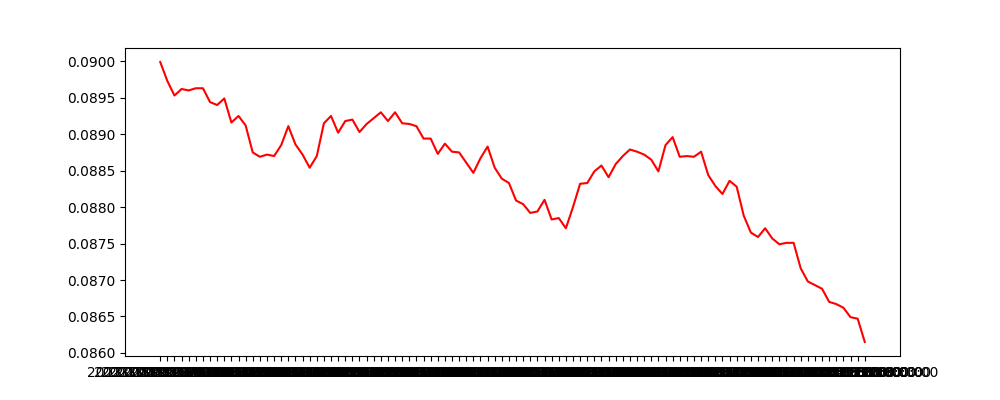

In [46]:
plt.close()
plt.figure(figsize=(10,4))
plt.plot(file['Date'][:100],file['Close'][:100],color='red')
plt.show()

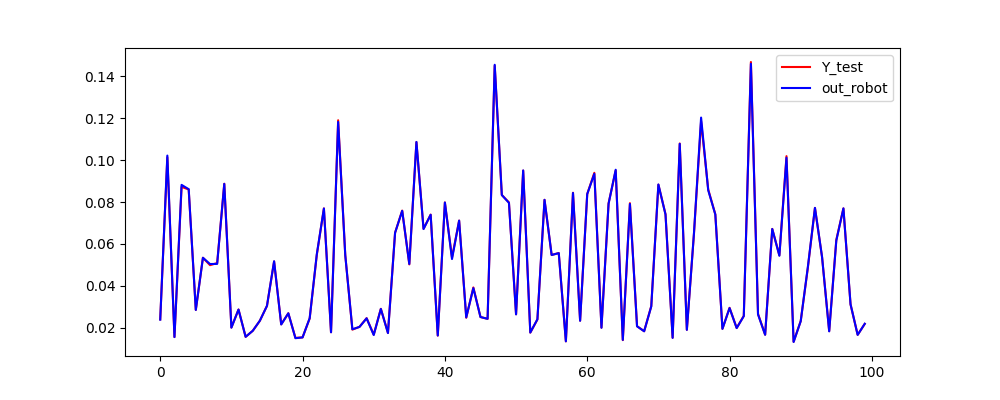

In [47]:
plt.close()
plt.figure(figsize=(10,4))
plt.plot(orginal_Y_test[:100],color='red')
plt.plot(orginal_out_robot[:100],color='blue')
plt.legend(['Y_test','out_robot'])
plt.show()

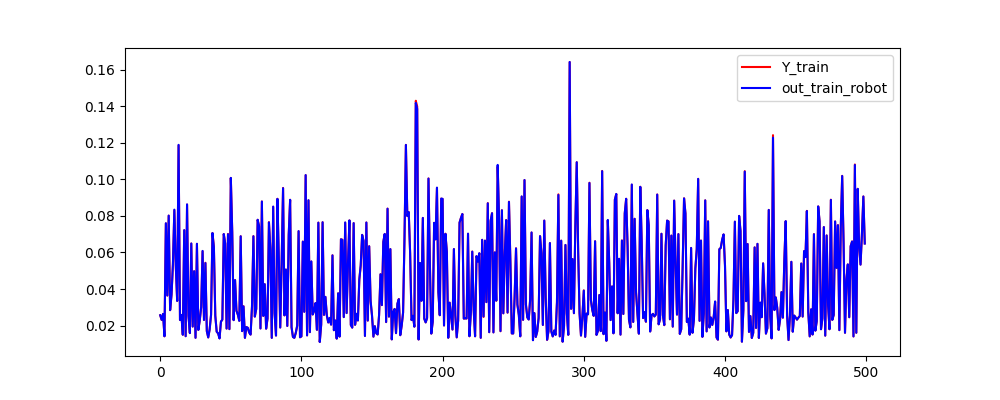

In [48]:
plt.close()
plt.figure(figsize=(10,4))
plt.plot(orginal_Y_train[:500],color='red')
plt.plot(orginal_out_train_robot[:500],color='blue')
plt.legend(['Y_train','out_train_robot'])
plt.show()